## Week 5 Discussion

### Load Data

In [4]:
import  pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Load data
url = "https://raw.githubusercontent.com/carmengg/eds220-hwk-1/main/data/earthquake_data.csv"
url2 = "data/ne_110m_admin_0_countries/ne_110m_admin_0_countries.shp"

earthquake = pd.read_csv(url)
countries = gpd.read_file(url2)

In [ ]:
earthquake.head()

,time,latitude,longitude,depth,mag,id,place,type
0,2014-01-31 23:53:37.000,60.252000,-152.708100,90.20,1.10,ak11155107,"26km S of Redoubt Volcano, Alaska",earthquake
1,2014-01-31 23:48:35.452,37.070300,-115.130900,0.00,1.33,nn00436847,"32km S of Alamo, Nevada",earthquake
2,2014-01-31 23:47:24.000,64.671700,-149.252800,7.10,1.30,ak11151142,"12km NNW of North Nenana, Alaska",earthquake
3,2014-01-31 23:30:54.000,63.188700,-148.957500,96.50,0.80,ak11151135,"22km S of Cantwell, Alaska",earthquake
4,2014-01-31 23:30:52.210,32.616833,-115.692500,10.59,1.34,ci37171541,"10km WNW of Progreso, Mexico",earthquake
...,...,...,...,...,...,...,...,...
120103,2014-12-01 00:10:16.000,60.963900,-146.762900,14.80,3.80,ak11453391,"29km SW of Valdez, Alaska",earthquake
120104,2014-12-01 00:09:39.000,58.869100,-154.415900,108.40,2.40,ak11453395,"102km SSE of Old Iliamna, Alaska",earthquake
120105,2014-12-01 00:09:25.350,38.843498,-122.825836,2.37,0.43,nc72358451,"9km WNW of Cobb, California",earthquake
120106,2014-12-01 00:05:54.000,65.152100,-148.992000,9.50,0.40,ak11453390,"57km NW of Ester, Alaska",earthquake


In [13]:
# Make earthquake data geometry

# Create points from latitude and longitude
points = gpd.points_from_xy(earthquake['longitude'], 
                            earthquake['latitude'])

# Create geodataframe
earthquakes = gpd.GeoDataFrame(earthquake,    # Data
                                geometry=points, # Specify geometry column
                                crs='EPSG:4326'  # Specify CRS
                                )

In [ ]:
# Check crs match
print(countries.crs)
print(earthquakes.crs)

EPSG:4326
EPSG:4326


In [17]:
# Show columns
earthquakes.columns

# Filter earthquakes (mag)
earthquakes_L = earthquakes[(earthquakes['mag'] >= 6.5) & (earthquakes['type'] >= "earthquake")]
earthquakes_L.head()


,time,latitude,longitude,depth,mag,id,place,type,geometry
9062,2014-01-01 16:03:29.000,-13.8633,167.2490,187.00,6.5,usc000lvb5,"32km W of Sola, Vanuatu",earthquake,POINT (167.24900 -13.86330)
12142,2014-02-18 09:27:13.120,14.6682,-58.9272,14.83,6.5,usc000mskt,"172km NNE of Bathsheba, Barbados",earthquake,POINT (-58.92720 14.66820)
14025,2014-02-12 09:19:49.060,35.9053,82.5864,10.00,6.9,usc000mnvj,"272km ESE of Hotan, China",earthquake,POINT (82.58640 35.90530)
15979,2014-02-07 08:40:13.550,-15.0691,167.3721,122.00,6.5,usc000mjye,"34km E of Port-Olry, Vanuatu",earthquake,POINT (167.37210 -15.06910)
17606,2014-02-02 09:26:37.820,-32.9076,-177.8806,44.26,6.5,usc000mfm0,"189km SSE of L'Esperance Rock, New Zealand",earthquake,POINT (-177.88060 -32.90760)


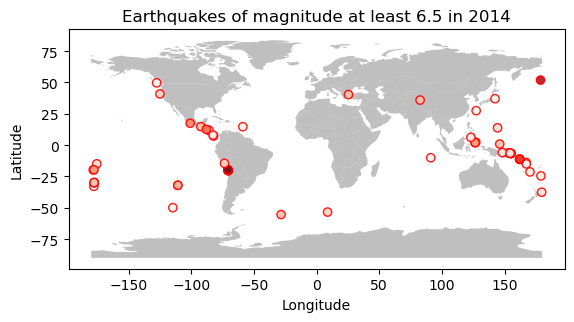

In [ ]:
# Recreate plot

# Initialize empty figure
fig, ax = plt.subplots()

# Add countries data to axes
countries.plot(ax=ax,         # Add plot to axes
                 alpha=0.5,     # Adjust transparency
                 color='grey'  # Update point color
                 )

# Add earthquakes_L data to axes
earthquakes_L.plot(ax=ax,         # Add plot to axes
                 alpha=0.5,     # Adjust transparency
                 column = 'mag',
                 cmap="Reds", # Update point color by mag
                 edgecolor = "red" # Color point outline
                 )

# Update axes 
ax.set_title('Earthquakes of magnitude at least 6.5 in 2014')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
#plt.colorbar(label="moment magnitude")

# Display figure
plt.show()